# 02 · Modeling walkthrough

All results here come from one command, which writes to the warehouse (schema `ml`) and `reports/`:

```bash
make train        # = uv run python -m aml.train
```

This notebook only reads those outputs and explains them, so it runs in seconds and always matches
the last training run.

In [1]:
from pathlib import Path
import json

import duckdb
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
con = duckdb.connect(str(ROOT / "data" / "warehouse" / "aml.duckdb"), read_only=True)
summary = json.loads((REPORTS / "metrics.json").read_text())
pd.set_option("display.width", 160)

## Framing

- **Unit:** one account in one 5-day window. Features summarize what the account did in the window;
  the label says whether any of its transfers in that window was laundering.
- **Split by time:** train on Sep 1–5, test on Sep 6–10. A random split would let the model learn an
  account's later behavior and be graded on its earlier behavior.
- **Imbalance:** under 1% of account-windows are positive, so the headline metric is PR-AUC and accuracy
  is never reported (flagging nobody would score above 99%).

In [2]:
pd.Series({k: summary[k] for k in
    ["train_window", "test_window", "window_days", "train_rows", "train_positives",
     "test_rows", "test_positives", "graph_features", "hgb_params"]})

train_window                                              2022-09-01
test_window                                               2022-09-06
window_days                                                        5
train_rows                                                    512312
train_positives                                                 2799
test_rows                                                     372954
test_positives                                                  3357
graph_features                                                  True
hgb_params         {'learning_rate': 0.1, 'max_leaf_nodes': 63, '...
dtype: object

## Feature mart

In [3]:
con.sql("""
select window_start, count(*) as accounts, sum(is_suspicious) as positives,
       round(100 * avg(is_suspicious), 2) as positive_pct
from marts.fct_account_features group by 1 order by 1
""").df()

,window_start,accounts,positives,positive_pct
0,2022-09-01,512312,2799.0,0.55
1,2022-09-06,372954,3357.0,0.90


In [4]:
con.sql("""
select is_suspicious,
       median(tx_count) as tx_count, median(fan_out) as fan_out, median(fan_in) as fan_in,
       round(avg(share_ach), 3) as share_ach, round(avg(share_cross_bank), 3) as share_cross_bank,
       round(avg(flow_balance), 3) as flow_balance
from marts.fct_account_features group by 1 order by 1
""").df()

,is_suspicious,tx_count,fan_out,fan_in,share_ach,share_cross_bank,flow_balance
0,0,4.0,1.0,1.0,0.167,0.769,0.283
1,1,11.0,1.0,2.0,0.391,0.822,0.297


## Models

| Model | Role |
|---|---|
| `LogisticRegression(class_weight="balanced")` | linear baseline |
| `HistGradientBoostingClassifier` | main model, tuned on 20% of train accounts |
| `RandomForestClassifier` | tree-ensemble comparison |
| `IsolationForest` | unsupervised: never sees labels |
| statsmodels `Logit` | interpretable coefficients |
| total-volume rule | what a naive "review the biggest accounts" rule would catch |

All sklearn models share one `ColumnTransformer`: log1p + scaling for heavy-tailed counts and amounts,
scaling for shares, one-hot for the dominant payment format.

## Ranking quality on the test window

In [5]:
pd.DataFrame(summary['metrics']).set_index('model')

,pr_auc,roc_auc,prevalence,recall_at_precision_50,recall_at_precision_80
model,,,,,
hist_gradient_boosting,0.2654,0.8755,0.009,0.1942,0.1597
random_forest,0.2095,0.8600,0.009,0.1180,0.0935
statsmodels_logit,0.0902,0.8185,0.009,0.0209,0.0122
logistic_regression,0.0864,0.8264,0.009,0.0140,0.0089
isolation_forest,0.0196,0.6335,0.009,0.0048,0.0042
rule_total_volume,0.0163,0.6986,0.009,0.0000,0.0000


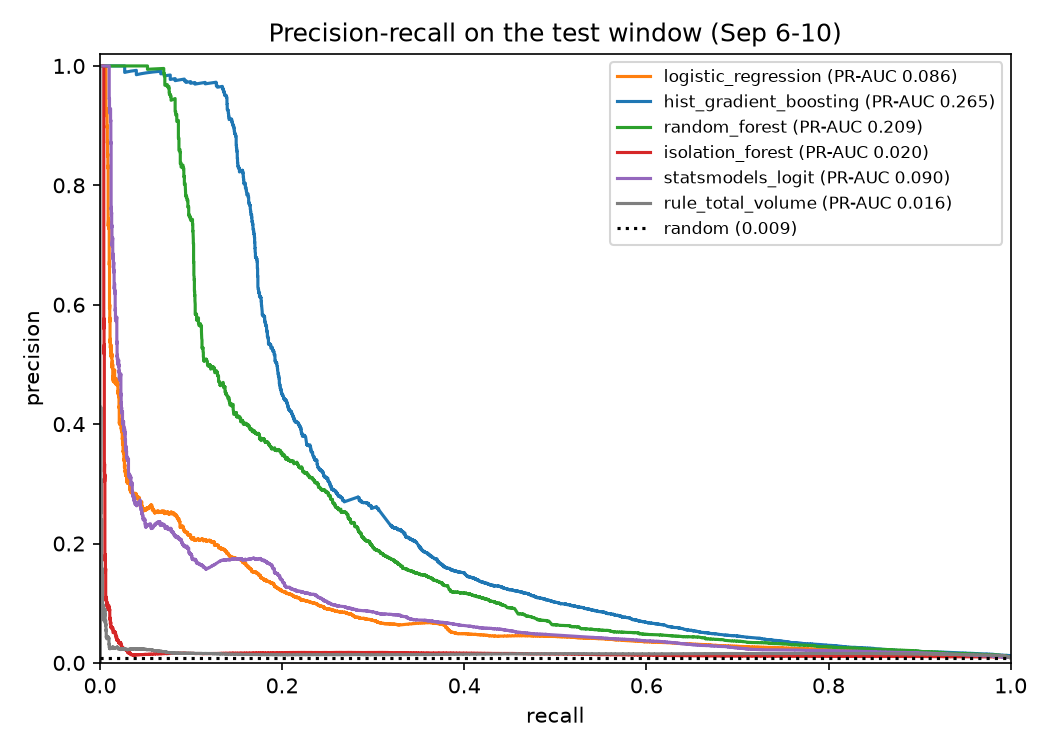

In [6]:
display(Image(REPORTS / 'figures' / 'pr_curves.png'))

Gradient boosting leads on PR-AUC, with the random forest second. Both linear models trail well
behind: suspicion depends on combinations (small account + mostly ACH + cross-bank + money passing
through) that a linear score cannot express. Isolation Forest barely beats random. Laundering accounts
in this data are not unusual in general, only unusual in specific ways, and an unsupervised model has
no way to know which ways matter.

## Calibration

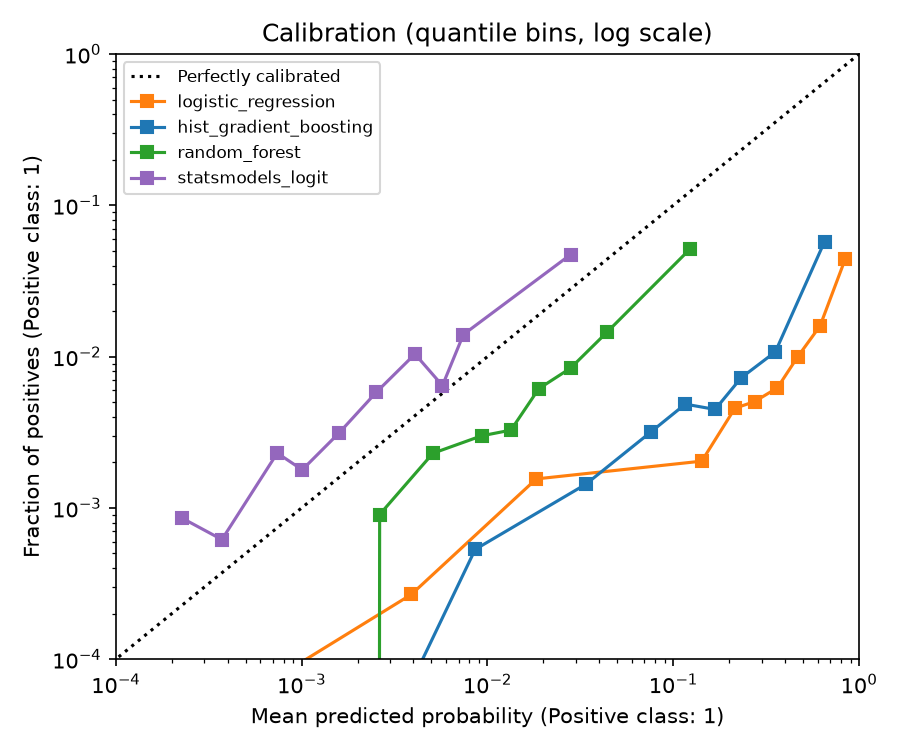

In [7]:
display(Image(REPORTS / 'figures' / 'calibration.png'))

Models trained with balanced class weights (logistic regression, gradient boosting) over-state
probabilities: weighting positives up inflates every score. The unweighted statsmodels logit sits *above*
the diagonal because the positive rate rose from 0.55% in train to 0.90% in test. Ranking is what the alert
budget uses, so this does not change the business result, but the scores should not be read as
probabilities without recalibrating on recent data.

## Interpretable model: odds ratios per standard deviation

In [8]:
pd.read_csv(REPORTS / 'logit_coefficients.csv', index_col='term')

,coef_per_sd,std_err,odds_ratio_per_sd,or_ci_low,or_ci_high,p_value
term,,,,,,
log1p_fan_out,0.8948,0.0411,2.4468,2.2576,2.6519,0.0000
log1p_fan_in,0.8357,0.0333,2.3064,2.1605,2.4621,0.0000
log1p_tx_in_count,0.7871,0.0479,2.1970,2.0000,2.4135,0.0000
share_ach,0.7465,0.0253,2.1095,2.0077,2.2166,0.0000
share_cross_bank,-0.7272,0.0392,0.4833,0.4475,0.5218,0.0000
log1p_max_tx_per_hour,-0.5604,0.0271,0.5710,0.5415,0.6021,0.0000
log1p_tx_out_count,-0.4107,0.0440,0.6632,0.6084,0.7228,0.0000
in_short_cycle,0.2701,0.0347,1.3101,1.2239,1.4024,0.0000
round_trip,-0.2398,0.0351,0.7868,0.7345,0.8428,0.0000


Holding the other terms fixed (all terms standardized, so effects are per one standard deviation):

- **Fan-out and fan-in** are the strongest signals: each SD more distinct counterparties multiplies the
  odds of laundering by about 2.4 and 2.3. This is the fan-out / fan-in typology made visible.
- **Share of ACH** roughly doubles the odds per SD. ACH carries ~87% of laundering transfers in the data.
- **Received transfer count** raises the odds, while **sent transfer count** and **peak transfers per hour**
  lower them once fan-out is accounted for: high-frequency senders to few counterparties look like
  ordinary businesses (payroll, merchants), not layering.
- **Cross-bank share** lowers the odds per SD once ACH share is in the model. Most ordinary transfers in this
  data are already cross-bank, so the term mostly separates account types rather than marking risk.
- **Short cycles** (length 2–4) raise the odds by ~30%, while pure **round trips** (A→B→A) lower them:
  in this data, direct back-and-forth is common between ordinary trading partners.
- **Flow balance** and **Bitcoin share** are not significant after the other terms.

These are associations in synthetic data, not causal effects, and the linear model is far weaker than
gradient boosting at ranking. Its value is in explaining *which* behaviors matter.